## 1. Setup

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC


from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    make_scorer,
    precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import pandas as pd
import matplotlib.pyplot as plt


%run ./2_preprocessing.ipynb

Numerical: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


,IQR_lower,IQR_upper,Flagged_count,Flagged_min,Flagged_max
Age,15.50,27.50,2,28.0,28.00
Sleep_Hours,3.75,9.75,9,3.6,10.00
Study_Hours_Per_Week,4.00,36.00,7,2.4,38.30
GPA,1.60,3.52,5,1.5,3.66
Social_Media_Hours,3.05,9.05,10,2.1,10.00
Screen_Time_Hours,3.95,13.15,7,3.3,14.00
Attendance_Rate,65.35,104.95,10,54.4,65.30


,Student_ID,Study_Hours_Per_Week
866,STU0867,2.4
1042,STU1043,2.7
453,STU0454,3.2
519,STU0520,3.6
340,STU0341,3.9
937,STU0938,37.5
716,STU0717,38.3


,num__Age,num__Year_of_Study,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate,binary__Part_Time_Job,binary__Previous_Mental_Health_History,ordinal__Physical_Activity,ordinal__Diet_Quality,nominal__Gender_Female,nominal__Gender_Male,nominal__Gender_Non-binary
726,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,0.713748,0.643008,-1.244652,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
1384,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,-0.842691,0.368687,-0.465696,0.0,0.0,1.581473,0.080487,1.0,0.0,0.0
1579,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,-0.305988,0.752736,0.772288,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
1098,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,0.821088,-0.948052,-0.215317,0.0,0.0,0.191167,0.080487,1.0,0.0,0.0
582,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,0.660077,0.697872,-1.453301,1.0,1.0,1.581473,0.080487,1.0,0.0,0.0


Training shape: (1600, 17)
Test shape: (400, 17)
Missing values: 0


,Count,Percent
Mental_Health_Risk,,
High,544,34.0
Medium,528,33.0
Low,528,33.0


,Count,Percent
Mental_Health_Risk,,
High,544,34.0
Medium,528,33.0
Low,528,33.0


## 2. Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=1
    ),
    "SVM": CalibratedClassifierCV(estimator=SVC(kernel="rbf"), ensemble=False),
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(
        [("preprocessor", clone(preprocessor)), ("model", model)]
    )

## 3. Cross-validation strategy

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 4. Evaluation metrics

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
    "roc_auc": "roc_auc_ovr_weighted",
}

## 5. Train and evaluate

In [ ]:
results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise",
    )

    results.append(
        {
            "Model": name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC_AUC": scores["test_roc_auc"].mean(),
        }
    )

comparison = pd.DataFrame(results).set_index("Model").sort_values("F1", ascending=False)

display(comparison.round(3))


Logistic Regression
              precision    recall  f1-score   support

         Low      0.811     0.812     0.812       528
      Medium      0.628     0.627     0.627       528
        High      0.812     0.812     0.812       544

    accuracy                          0.751      1600
   macro avg      0.751     0.751     0.751      1600
weighted avg      0.751     0.751     0.751      1600



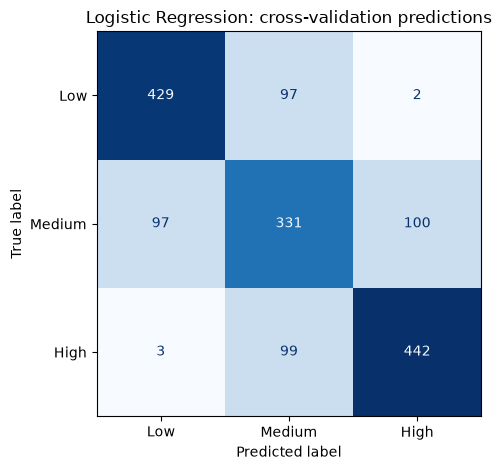


Random Forest
              precision    recall  f1-score   support

         Low      0.720     0.746     0.733       528
      Medium      0.541     0.494     0.517       528
        High      0.750     0.787     0.768       544

    accuracy                          0.677      1600
   macro avg      0.670     0.676     0.673      1600
weighted avg      0.671     0.677     0.673      1600



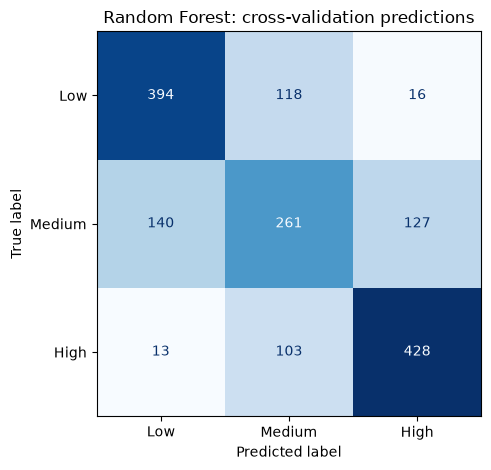


SVM
              precision    recall  f1-score   support

         Low      0.792     0.792     0.792       528
      Medium      0.576     0.598     0.587       528
        High      0.788     0.757     0.772       544

    accuracy                          0.716      1600
   macro avg      0.718     0.716     0.717      1600
weighted avg      0.719     0.716     0.717      1600



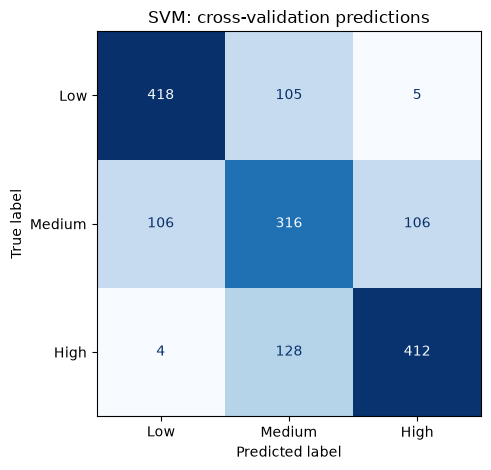

In [54]:
risk_order = ["Low", "Medium", "High"]
oof_predictions = {}

for name, pipeline in pipelines.items():

    predictions = cross_val_predict(pipeline, X_train, y_train, cv=cv, n_jobs=1)

    oof_predictions[name] = predictions

    print(f"\n{name}")

    print(
        classification_report(
            y_train, predictions, labels=risk_order, digits=3, zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train, predictions, labels=risk_order, cmap="Blues", colorbar=False
    )

    plt.title(f"{name}: cross-validation predictions")
    plt.tight_layout()
    plt.show()